# Part A: Robust Horizontal Slicing Pipeline

### Objective - Design a reusable Python pipeline to slice a 3D mesh into 2D layers and represent each layer as clean planar geometry.

In [1]:
# Importing the required libraries
import os 
import trimesh
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely
from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from shapely.geometry.polygon import orient
import shutil

In [2]:
# Defining the paths to the all 3d files
path = "obj1.stl"

### 1. Load a triangulated 3D mesh (.STL or .OBJ) using trimesh.

In [3]:
# Loading the 3D meshes from the specified paths
mesh = trimesh.load_mesh(path)

### 2. Compute the axis-aligned bounding box of the mesh.

In [4]:
bound = mesh.bounds
bound

array([[ 0.00000000e+00, -7.17741838e-17,  0.00000000e+00],
       [ 2.00000000e+01,  2.00000000e+01,  2.00000000e+01]])

In [5]:
trimesh.bounds.corners(bound)

array([[ 0.00000000e+00, -7.17741838e-17,  0.00000000e+00],
       [ 2.00000000e+01, -7.17741838e-17,  0.00000000e+00],
       [ 2.00000000e+01,  2.00000000e+01,  0.00000000e+00],
       [ 0.00000000e+00,  2.00000000e+01,  0.00000000e+00],
       [ 0.00000000e+00, -7.17741838e-17,  2.00000000e+01],
       [ 2.00000000e+01, -7.17741838e-17,  2.00000000e+01],
       [ 2.00000000e+01,  2.00000000e+01,  2.00000000e+01],
       [ 0.00000000e+00,  2.00000000e+01,  2.00000000e+01]])

In [6]:
# Max and min z values for slicing
z_min = round(bound[0][2],7)
z_max = round(bound[1][2],7)
print("Z min and max for mesh:", z_min, z_max)

Z min and max for mesh: 0.0 20.0


### 3. Generate a list of horizontal slicing planes parallel to the XY plane:
##### a. Plane spacing should be parameterized.
##### b. Slicing should start from the minimum Z and end at maximum Z.

In [7]:
# Taking Layer Height from user as slicing parameter
layer_height = float(input("Enter the layer height for slicing: "))

In [8]:
# Generate horizontal slicing plane heights
z_coords = np.round(
    np.arange(z_min, z_max, layer_height),
    7
).tolist()

for i in z_coords: print(i, end=" ")

0.0 0.2 0.4 0.6 0.8 1.0 1.2 1.4 1.6 1.8 2.0 2.2 2.4 2.6 2.8 3.0 3.2 3.4 3.6 3.8 4.0 4.2 4.4 4.6 4.8 5.0 5.2 5.4 5.6 5.8 6.0 6.2 6.4 6.6 6.8 7.0 7.2 7.4 7.6 7.8 8.0 8.2 8.4 8.6 8.8 9.0 9.2 9.4 9.6 9.8 10.0 10.2 10.4 10.6 10.8 11.0 11.2 11.4 11.6 11.8 12.0 12.2 12.4 12.6 12.8 13.0 13.2 13.4 13.6 13.8 14.0 14.2 14.4 14.6 14.8 15.0 15.2 15.4 15.6 15.8 16.0 16.2 16.4 16.6 16.8 17.0 17.2 17.4 17.6 17.8 18.0 18.2 18.4 18.6 18.8 19.0 19.2 19.4 19.6 19.8 

In [9]:
# Horizontal slicing planes for the meshes
slicing_planes = [
    {
        "origin": [0, 0, round(float(z), 7)],
        "normal": [0, 0, 1]
    }
    for z in z_coords
]
len(slicing_planes)

100

In [10]:
# Checking the values of the first 10 slicing planes
for plane in slicing_planes[:10]:
    print(plane, end=" ")

{'origin': [0, 0, 0.0], 'normal': [0, 0, 1]} {'origin': [0, 0, 0.2], 'normal': [0, 0, 1]} {'origin': [0, 0, 0.4], 'normal': [0, 0, 1]} {'origin': [0, 0, 0.6], 'normal': [0, 0, 1]} {'origin': [0, 0, 0.8], 'normal': [0, 0, 1]} {'origin': [0, 0, 1.0], 'normal': [0, 0, 1]} {'origin': [0, 0, 1.2], 'normal': [0, 0, 1]} {'origin': [0, 0, 1.4], 'normal': [0, 0, 1]} {'origin': [0, 0, 1.6], 'normal': [0, 0, 1]} {'origin': [0, 0, 1.8], 'normal': [0, 0, 1]} 

### 4. For each slicing plane:
##### a. Compute the intersection between the plane and the mesh.

In [11]:
intersections = []
empty_slices = []

for i, layer in enumerate(z_coords):
    slice = mesh.section(
        plane_origin=[0, 0, layer],
        plane_normal=[0, 0, 1]
    )

    

    # Convert the 3D slice to 2D
    if slice is not None and len(slice.vertices) > 0:
        slice_2d = trimesh.path.Path2D(
            entities=slice.entities,
            vertices=slice.vertices[:, :2]
        )
        intersections.append(slice_2d)
    else:
        empty_slices.append(i)
        intersections.append(None)

# Number of slices
intersections_len = len(intersections)
print(f"Number of slices: {intersections_len}")

# Printing empty slices and their corresponding intersections
for i in empty_slices:
    print(f"Empty slice at index {i}: {intersections[i]}")

Number of slices: 100


##### b. Handle cases where the plane does not intersect the mesh.

In [12]:
# Used 2 pointers method to replace multiple None value or empty slices from the intersections list with the next available slice. This is done to ensure that the intersections list has valid slices for further processing.
i = 0 
j = 0

while i < intersections_len:
    if intersections[i] is None or len(intersections[i].vertices) == 0:
        
        j = i + 1
        while j < intersections_len and (intersections[j] is None or len(intersections[j].vertices) == 0):
            j += 1

        if j >= intersections_len or intersections[j] is None or len(intersections[j].vertices) == 0:
            break

        while i < j:
            intersections[i] = intersections[j] 
            i += 1
        
        i = j 

    else:
        i += 1

for i in intersections[:10]:
    print(i)

<trimesh.Path2D(vertices.shape=(4, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>
<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>


<trimesh.Path2D(vertices.shape=(4, 2), len(entities)=1)>


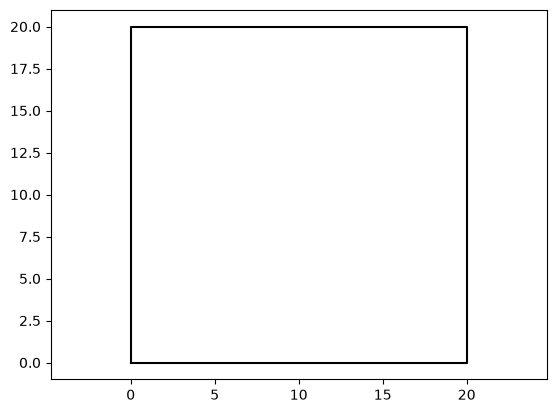

<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>


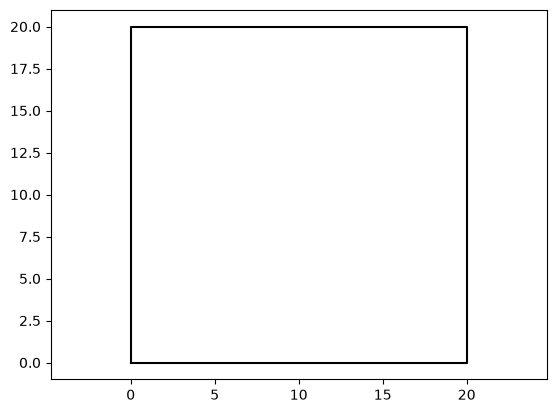

<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>


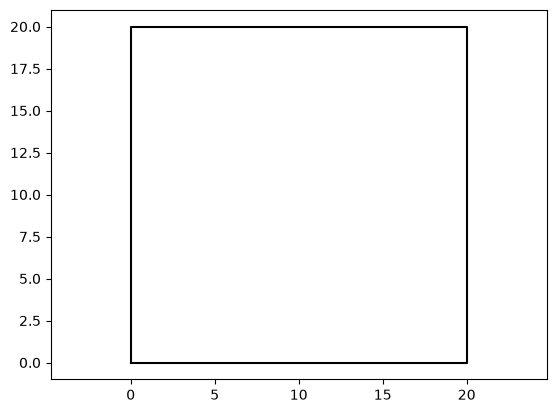

<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>


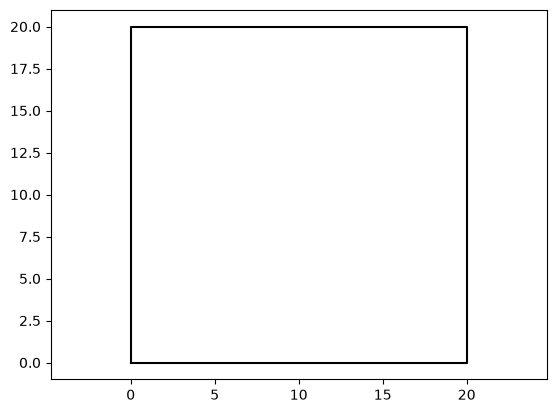

<trimesh.Path2D(vertices.shape=(20, 2), len(entities)=1)>


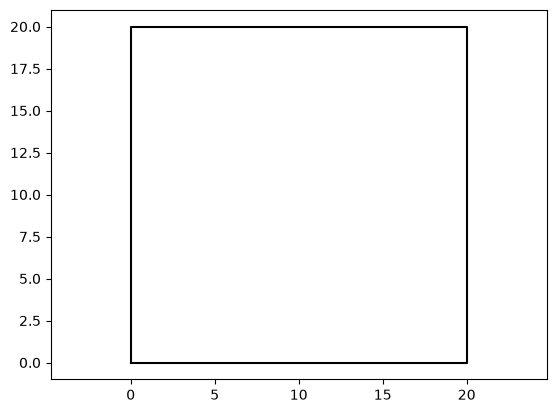

In [13]:
for i in intersections[:5]:
    print(i)
    if i is not None:
        i.show()

### 5. Convert the resulting intersection curves into 2D coordinates.

In [14]:
coordinates = []
for i in intersections:
    coordinates.append(i.vertices)

In [15]:
for i in coordinates[:5]:
    print(i)

[[ 0.  0.]
 [20.  0.]
 [ 0. 20.]
 [20. 20.]]
[[ 0.00000000e+00  0.00000000e+00]
 [ 6.57789896e-02  7.82678907e-19]
 [ 2.73868191e-01  9.30783668e-19]
 [ 3.61481404e-01  9.30783668e-19]
 [ 6.81103733e-01  9.30783668e-19]
 [ 1.95943994e+01  9.30783668e-19]
 [ 1.96912002e+01 -1.16052926e-18]
 [ 1.99260602e+01  1.35485617e-18]
 [ 2.00000000e+01  0.00000000e+00]
 [ 2.00000000e+01  5.92551565e-02]
 [ 2.00000000e+01  1.90418800e-01]
 [ 2.00000000e+01  4.77390977e-01]
 [ 2.00000000e+01  5.65470851e-01]
 [ 2.00000000e+01  1.94894687e+01]
 [ 2.00000000e+01  1.97930817e+01]
 [ 0.00000000e+00  1.98000000e+01]
 [ 2.00000000e+01  1.99293954e+01]
 [ 0.00000000e+00  2.00000000e+01]
 [ 2.00000000e-01  2.00000000e+01]
 [ 2.00000000e+01  2.00000000e+01]]
[[ 0.00000000e+00  0.00000000e+00]
 [ 1.31557979e-01  1.56535781e-18]
 [ 5.47736381e-01  1.86156734e-18]
 [ 7.22962809e-01  1.86156734e-18]
 [ 1.36220747e+00  1.86156734e-18]
 [ 1.91887988e+01  1.86156734e-18]
 [ 1.93824005e+01 -2.32105851e-18]
 [ 1.9852

### 6. Store each slice as a structured object containing: 
##### a. Z height 
##### b. Raw curves 
##### c. 2D projected geometry 

In [16]:
# creating dictionary with keys as Z_height, Raw_curves, 2D_projected_geometry
final_output = []
for i in range(len(z_coords)):
    final_output.append({
        "Z_height": z_coords[i],
        "Raw_curves": intersections[i],
        "2D_projected_geometry": coordinates[i].tolist()
    })

In [17]:
# Convert the list of dictionaries to a DataFrame
df = pd.DataFrame(final_output)

In [18]:
# print first 10 rows of the DataFrame
df.head(10)

,Z_height,Raw_curves,2D_projected_geometry
0,0.0,"<trimesh.Path2D(vertices.shape=(4, 2), len(ent...","[[0.0, 0.0], [20.0, 0.0], [0.0, 20.0], [20.0, ..."
1,0.2,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.0657789896011586, 7.8267890693..."
2,0.4,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.1315579792023172, 1.5653578138..."
3,0.6,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.19733696880347582, 2.348036720..."
4,0.8,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.2631159584046344, 3.1307156277..."
5,1.0,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.328894948005793, 3.91339453465..."
6,1.2,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.39467393760695163, 4.696073441..."
7,1.4,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.46045292720811015, 5.478752348..."
8,1.6,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.5262319168092688, 6.2614312554..."
9,1.8,"<trimesh.Path2D(vertices.shape=(20, 2), len(en...","[[0.0, 0.0], [0.5920109064104274, 7.0441101623..."


# Part B: Slice Topology Classification & Cleaning 
### Objective - Correctly classify and clean slice geometry into outer boundaries and holes. 

### 1. Take the 2D slice output from Part A.

In [19]:
slices = intersections

### 2. Convert all slice contours into shapely geometries.

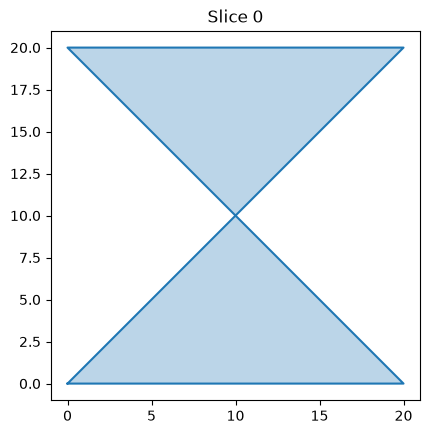

In [20]:
shapely_geometries_without_discrete = []

for coords in coordinates:
    polygons = [Polygon(coords)]
    
    shapely_geometries_without_discrete.append(polygons)

fig, ax = plt.subplots()

for j, poly in enumerate(shapely_geometries_without_discrete[0]):
        x, y = poly.exterior.xy
        ax.plot(x, y, label=f"Polygon {j}")
        ax.fill(x, y, alpha=0.3)

ax.set_title(f"Slice {0}")
ax.set_aspect("equal")
plt.show()

In [21]:
# Taking thresold area as input
threshold_area = round(float(input("Enter area threshold: ")), 7)

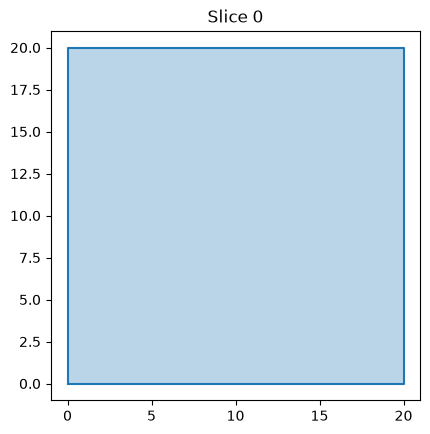

In [22]:
# Converting 2D slice countours into shapely geometries
shapely_geometries = []

for slice_mesh in slices:
    contours = slice_mesh.discrete

    # Storing all valid polygons of this layer in a list
    polygons = []

    for c in contours:
        # Converting countour into polygon 
        poly = Polygon(c)

        # skiping any degenerated contours or very small polygons below an area threshold 
        if poly.is_empty or not poly.is_valid or poly.area < threshold_area :
            continue

        # Ensure consistent exterior orientation (CCW)
        poly = orient(poly, sign=1.0)
        polygons.append(poly)

    # Sort the polygons by area in descending order
    polygons.sort(key=lambda p: p.area, reverse=True)

    # Appending all sorted polygons 
    shapely_geometries.append(polygons)

fig, ax = plt.subplots()

for j, poly in enumerate(shapely_geometries[0]):
        x, y = poly.exterior.xy
        ax.plot(x, y, label=f"Polygon {j}")
        ax.fill(x, y, alpha=0.3)

ax.set_title(f"Slice {0}")
ax.set_aspect("equal")
plt.show()

In [23]:
from shapely.geometry import Polygon

for i, poly in enumerate(shapely_geometries[0]):
        print(f"Polygon {i}: {'CCW' if poly.exterior.is_ccw else 'CW'}")

Polygon 0: CCW


### 3. For each slice: 
#### a. Identify outer boundaries. 
#### b. Identify inner holes. 

In [24]:
# separating outer boundaries and inner holes for each layer of polygons
outer_boundaries = []
inner_holes = []

for layer in shapely_geometries:
    i = 1
    polygon_count = len(layer)

    # Initialize a list to keep track of the parity of each polygon's boundary (0 for outer boundary, 1 for inner hole)
    boundary_parity = [0] * polygon_count

    while i < polygon_count:
        j =  i - 1 
        cnt = 0
        while j >= 0: 
            # If parents are found, toggle the parity of the current polygon based on its parent polygon's parity and break the loop
            if layer[j].contains(layer[i]):
                boundary_parity[i] = boundary_parity[j] ^ 1
                break 
            j -= 1

        i += 1

    # Create an empty list for the current layer
    outer_boundaries.append([])
    inner_holes.append([])

    # Separate the outer boundaries and inner holes based on the boundary_parity list
    for i, status in enumerate(boundary_parity):
        if status == 0:
            outer_boundaries[-1].append(layer[i])
        else:
            inner_holes[-1].append(layer[i])

print(len(outer_boundaries), len(inner_holes))

100 100


### Interpreted Expected Result 
    For each layer polygon: 
        Use the Layer Height as the folder name 
    Inside that folder: 
        Store Inner boundaries plot separately 
        Store Outer boundaries plot separately 

In [25]:
# defining a function for plotting polygons 
minx = bound[0][0]
maxx = bound[1][0]
miny = bound[0][1]
maxy = bound[1][1]

def plot_polygons(polygons, title, save_path, color):
    fig, ax = plt.subplots(figsize=(8, 8))

    for poly in polygons:
        x, y = poly.exterior.xy
        ax.plot(x, y, color=color, linewidth=1.2)

    # 
    ax.set_xlim(minx - 5, maxx + 5)
    ax.set_ylim(miny - 5, maxy + 5)

    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True)

    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

In [26]:
output_dir = "layer_plots"

# deleting previous folder with same directory
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)

# making new directory folder
os.makedirs(output_dir, exist_ok=True)

# iterating for each layer 
for i, layer_height in enumerate(z_coords):

    # Create a folder for each layer height
    layer_folder = os.path.join(output_dir, str(layer_height))
    os.makedirs(layer_folder, exist_ok=True)

    # Plot all outer polygons for this layer
    plot_polygons(
        outer_boundaries[i],
        f"Outer Boundaries - Layer {layer_height}",
        os.path.join(layer_folder, "outer_boundaries.png"),
        "blue"
    )

    # Plot all inner polygons for this layer
    plot_polygons(
        inner_holes[i],
        f"Inner Holes - Layer {layer_height}",
        os.path.join(layer_folder, "inner_holes.png"),
        "red"
    )